# Analysis
Analyze the effect of Planned peaks(Amazon Black Friday) and Unplanned emergency(Apple iOS Keyboard bugs), and compare.

In [1]:
import pandas as pd

df = pd.read_pickle("cleaned_df.pkl")
print("Data shape:", df.shape)
df.head()

Data shape: (507873, 9)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand,language
321,615,AmazonHelp,False,Tue Oct 31 22:29:00 +0000 2017,@115820 I'm sorry we've let you down! Without ...,[616],617,AmazonHelp,en
322,616,115820,True,Tue Oct 31 23:22:08 +0000 2017,@AmazonHelp 3 different people have given 3 di...,[618],615,AmazonHelp,en
323,618,AmazonHelp,False,Tue Oct 31 23:28:00 +0000 2017,@115820 We'd like to take a further look into ...,[619],616,AmazonHelp,en
324,619,115820,True,Tue Oct 31 23:32:26 +0000 2017,@AmazonHelp I frankly don't have the patience ...,[],618,AmazonHelp,en
325,617,115820,True,Tue Oct 31 22:16:32 +0000 2017,Way to drop the ball on customer service @1158...,[615],<NA>,AmazonHelp,en


Earliest customer message: 2017-10-04 00:03:07+00:00
Latest customer message: 2017-12-03 23:10:15+00:00


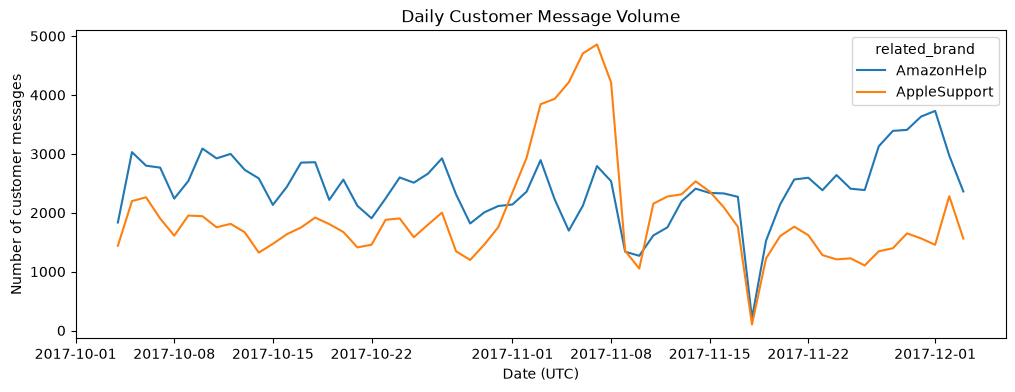

In [2]:
import matplotlib.pyplot as plt

df["created_at"] = pd.to_datetime(
    df["created_at"],
    format="%a %b %d %H:%M:%S %z %Y",
    utc=True
)

customer = df[
    (df["inbound"] == True)
    & (df["created_at"] >= "2017-10-04")
].copy()

print("Earliest customer message:", customer["created_at"].min())
print("Latest customer message:", customer["created_at"].max())

daily_counts = customer.groupby(
    [customer["created_at"].dt.date, "related_brand"]
).size().unstack(fill_value=0)

daily_counts.plot(figsize=(12, 4))
plt.xlabel("Date (UTC)")
plt.ylabel("Number of customer messages")
plt.title("Daily Customer Message Volume")
plt.show()

In [3]:
daily_counts.loc[
    pd.Timestamp("2017-11-15").date():
    pd.Timestamp("2017-11-29").date()
]

related_brand,AmazonHelp,AppleSupport
created_at,,
2017-11-15,2336,2360
2017-11-16,2328,2092
2017-11-17,2270,1760
2017-11-18,209,102
2017-11-19,1526,1224
2017-11-20,2142,1604
2017-11-21,2565,1763
2017-11-22,2594,1618
2017-11-23,2382,1281


In [4]:
nov18 = df[
    (df["created_at"] >= "2017-11-18")
    & (df["created_at"] < "2017-11-19")
]

hourly_counts = nov18.groupby(
    [nov18["created_at"].dt.hour, "related_brand"]
).size().unstack(fill_value=0)

hourly_counts = hourly_counts.reindex(range(24), fill_value=0)
hourly_counts.index.name = "Hour (UTC)"
hourly_counts

related_brand,AmazonHelp,AppleSupport
Hour (UTC),,
0,13,10
1,14,5
2,14,8
3,10,1
4,6,3
5,8,3
6,16,2
7,27,2
8,19,2


In [5]:
nearby = df[
    (df["created_at"] >= "2017-11-17")
    & (df["created_at"] < "2017-11-20")
]

message_counts = nearby.groupby(
    [
        nearby["created_at"].dt.date,
        "related_brand",
        "inbound"
    ]
).size().unstack(fill_value=0)

message_counts = message_counts.rename(
    columns={False: "Support messages", True: "Customer messages"}
)

message_counts

inbound                   Support messages  Customer messages
created_at related_brand                                     
2017-11-17 AmazonHelp                 1940               2270
           AppleSupport               1672               1760
2017-11-18 AmazonHelp                  184                209
           AppleSupport                 78                102
2017-11-19 AmazonHelp                 1267               1526
           AppleSupport               1135               1224

### Data Coverage Check

Both customer and support message counts are unusually low on
November 18, 2017, for AmazonHelp and AppleSupport.

The cause cannot be confirmed from the cleaned data alone.
We flag this date and will compare results with and without it
if it falls within a comparison period.

In [6]:
support = df[df["inbound"] == False][
    ["tweet_id", "author_id", "in_response_to_tweet_id", "created_at"]
].copy()

support = support.rename(columns={
    "tweet_id": "reply_id",
    "author_id": "reply_brand",
    "in_response_to_tweet_id": "customer_tweet_id",
    "created_at": "reply_at"
})

pairs = customer.merge(
    support,
    left_on=["tweet_id", "related_brand"],
    right_on=["customer_tweet_id", "reply_brand"],
    how="inner"
)

pairs = pairs[pairs["reply_at"] >= pairs["created_at"]]
first_replies = pairs.sort_values("reply_at").drop_duplicates("tweet_id")

cases = customer.merge(
    first_replies[["tweet_id", "reply_id", "reply_at"]],
    on="tweet_id",
    how="left"
)

cases["response_minutes"] = (
    cases["reply_at"] - cases["created_at"]
).dt.total_seconds() / 60

print("Customer messages:", len(cases))
print("Messages with a recorded reply:", cases["reply_at"].notna().sum())
print("Messages without a recorded reply:", cases["reply_at"].isna().sum())

cases[
    ["tweet_id", "related_brand", "created_at", "reply_at", "response_minutes"]
].head()

Customer messages: 266767
Messages with a recorded reply: 209938
Messages without a recorded reply: 56829


,tweet_id,related_brand,created_at,reply_at,response_minutes
0,616,AmazonHelp,2017-10-31 23:22:08+00:00,2017-10-31 23:28:00+00:00,5.866667
1,619,AmazonHelp,2017-10-31 23:32:26+00:00,NaT,NaN
2,617,AmazonHelp,2017-10-31 22:16:32+00:00,2017-10-31 22:29:00+00:00,12.466667
3,621,AmazonHelp,2017-10-31 22:19:34+00:00,2017-10-31 22:28:34+00:00,9.000000
4,627,AmazonHelp,2017-11-01 12:50:18+00:00,2017-11-01 12:53:34+00:00,3.266667


In [7]:
response_summary = cases.groupby(
    "related_brand"
)["response_minutes"].describe(
    percentiles=[0.5, 0.9, 0.99]
)

response_summary

,count,mean,std,min,50%,90%,99%,max
related_brand,,,,,,,,
AmazonHelp,111568.0,21.842175,295.016025,0.766667,12.033333,33.321667,124.322000,65653.433333
AppleSupport,98370.0,147.899596,197.154102,1.200000,72.000000,449.750000,623.705167,21181.933333


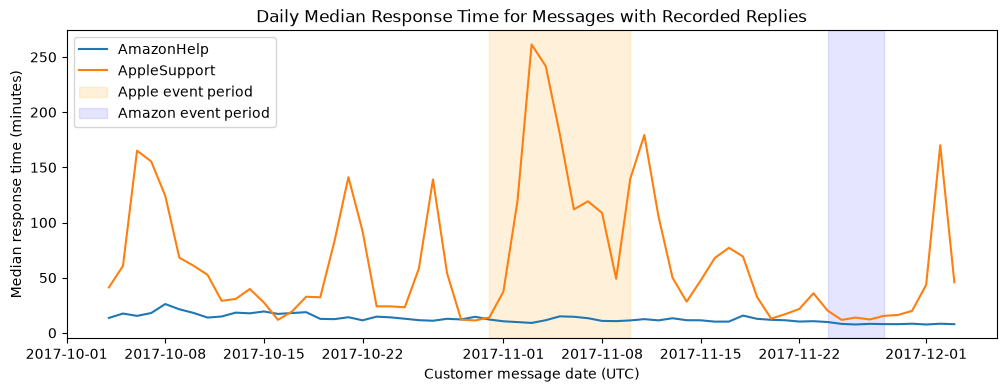

In [8]:
daily_response = cases.groupby(
    [cases["created_at"].dt.date, "related_brand"]
)["response_minutes"].median().unstack()

daily_response.plot(figsize=(12, 4))

plt.axvspan(
    pd.Timestamp("2017-10-31"),
    pd.Timestamp("2017-11-10"),
    color="orange",
    alpha=0.15,
    label="Apple event period"
)

plt.axvspan(
    pd.Timestamp("2017-11-24"),
    pd.Timestamp("2017-11-28"),
    color="blue",
    alpha=0.1,
    label="Amazon event period"
)

plt.xlabel("Customer message date (UTC)")
plt.ylabel("Median response time (minutes)")
plt.title("Daily Median Response Time for Messages with Recorded Replies")
plt.legend()
plt.show()

In [9]:
cases["period"] = "Other"

apple = cases["related_brand"] == "AppleSupport"
amazon = cases["related_brand"] == "AmazonHelp"

cases.loc[
    apple
    & (cases["created_at"] >= "2017-10-17")
    & (cases["created_at"] < "2017-10-31"),
    "period"
] = "Baseline"

cases.loc[
    apple
    & (cases["created_at"] >= "2017-10-31")
    & (cases["created_at"] < "2017-11-10"),
    "period"
] = "Event"

cases.loc[
    amazon
    & (cases["created_at"] >= "2017-11-10")
    & (cases["created_at"] < "2017-11-24"),
    "period"
] = "Baseline"

cases.loc[
    amazon
    & (cases["created_at"] >= "2017-11-24")
    & (cases["created_at"] < "2017-11-28"),
    "period"
] = "Event"

comparison = cases[cases["period"] != "Other"].copy()

summary = comparison.groupby(
    ["related_brand", "period"]
).agg(
    customer_messages=("tweet_id", "size"),
    recorded_replies=("response_minutes", "count"),
    median_minutes=("response_minutes", "median")
)

summary["p90_minutes"] = comparison.groupby(
    ["related_brand", "period"]
)["response_minutes"].quantile(0.9)

summary.round(2)

customer_messages  recorded_replies  median_minutes  \
related_brand period                                                          
AmazonHelp    Baseline              27589             21417           11.30   
              Event                 10562              8149            8.43   
AppleSupport  Baseline              23182             18862           47.38   
              Event                 34152             27492          154.68   

                        p90_minutes  
related_brand period                 
AmazonHelp    Baseline        31.25  
              Event           28.22  
AppleSupport  Baseline       401.88  
              Event          536.35

In [10]:
comparison["reply_within_24h"] = (
    comparison["response_minutes"] <= 24 * 60
)

summary["period_days"] = [14, 4, 14, 10]

summary["messages_per_day"] = (
    summary["customer_messages"] / summary["period_days"]
)

summary["reply_within_24h_rate"] = comparison.groupby(
    ["related_brand", "period"]
)["reply_within_24h"].mean()

summary[
    [
        "messages_per_day",
        "median_minutes",
        "p90_minutes",
        "reply_within_24h_rate"
    ]
].round(3)

messages_per_day  median_minutes  p90_minutes  \
related_brand period                                                    
AmazonHelp    Baseline          1970.643          11.300       31.250   
              Event               2640.5           8.433       28.220   
AppleSupport  Baseline          1655.857          47.383      401.878   
              Event               3415.2         154.675      536.348   

                        reply_within_24h_rate  
related_brand period                           
AmazonHelp    Baseline                  0.776  
              Event                     0.771  
AppleSupport  Baseline                  0.813  
              Event                     0.805

In [11]:
without_nov18 = comparison[
    comparison["created_at"].dt.date
    != pd.Timestamp("2017-11-18").date()
].copy()

sensitivity = without_nov18.groupby(
    ["related_brand", "period"]
).agg(
    customer_messages=("tweet_id", "size"),
    median_minutes=("response_minutes", "median"),
    reply_within_24h_rate=("reply_within_24h", "mean")
)

sensitivity["period_days"] = summary["period_days"].copy()
sensitivity.loc[("AmazonHelp", "Baseline"), "period_days"] = 13

sensitivity["messages_per_day"] = (
    sensitivity["customer_messages"] / sensitivity["period_days"]
)

sensitivity[
    ["messages_per_day", "median_minutes", "reply_within_24h_rate"]
].round(3)

messages_per_day  median_minutes  \
related_brand period                                       
AmazonHelp    Baseline          2106.154          11.267   
              Event               2640.5           8.433   
AppleSupport  Baseline          1655.857          47.383   
              Event               3415.2         154.675   

                        reply_within_24h_rate  
related_brand period                           
AmazonHelp    Baseline                  0.775  
              Event                     0.771  
AppleSupport  Baseline                  0.813  
              Event                     0.805

In [12]:
first_messages = comparison[
    comparison["in_response_to_tweet_id"].isna()
].copy()

first_summary = first_messages.groupby(
    ["related_brand", "period"]
).agg(
    customer_messages=("tweet_id", "size"),
    recorded_replies=("response_minutes", "count"),
    median_minutes=("response_minutes", "median"),
    reply_within_24h_rate=("reply_within_24h", "mean")
)

first_summary["p90_minutes"] = first_messages.groupby(
    ["related_brand", "period"]
)["response_minutes"].quantile(0.9)

first_summary.round(3)

customer_messages  recorded_replies  median_minutes  \
related_brand period                                                          
AmazonHelp    Baseline              11909             11271          10.867   
              Event                  4622              4422           8.000   
AppleSupport  Baseline              14173             13340          57.592   
              Event                 23469             21350         159.600   

                        reply_within_24h_rate  p90_minutes  
related_brand period                                        
AmazonHelp    Baseline                  0.946       31.250  
              Event                     0.957       28.017  
AppleSupport  Baseline                  0.941      419.330  
              Event                     0.909      539.218

### Check Using Conversation-Starting Messages

We repeat the comparison using customer messages with no recorded
parent tweet ID.

- Amazon's median response time decreases from 10.87 to 8.00 minutes.
  Its recorded 24-hour reply rate increases from about 94.6% to 95.7%.
- Apple's median response time increases from 57.59 to 159.60 minutes.
  Its recorded 24-hour reply rate decreases from about 94.1% to 90.9%.
- The direction of the response-time changes is consistent with
  the analysis using all customer messages.
- These results describe two company-event cases. Company differences
  and issue types may also contribute to the observed changes.

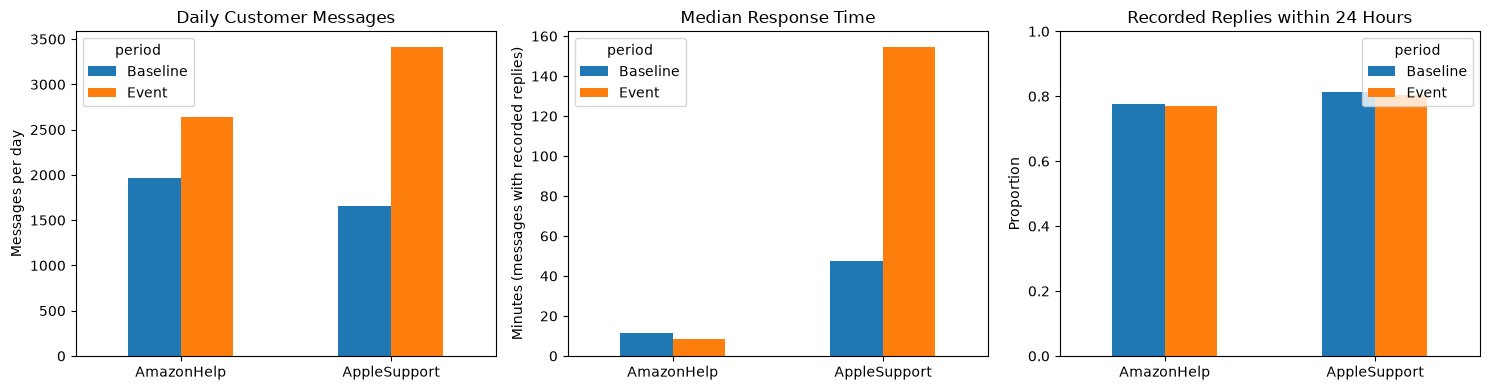

In [13]:
metrics = [
    "messages_per_day",
    "median_minutes",
    "reply_within_24h_rate"
]

titles = [
    "Daily Customer Messages",
    "Median Response Time",
    "Recorded Replies within 24 Hours"
]

ylabels = [
    "Messages per day",
    "Minutes (messages with recorded replies)",
    "Proportion"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric, title, ylabel in zip(axes, metrics, titles, ylabels):
    values = summary[metric].unstack("period")
    values = values[["Baseline", "Event"]]
    values.plot.bar(ax=ax, rot=0)

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)

axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### RQ2 Findings

- Amazon's daily customer message count increased from about 1,971
  to 2,641 during Black Friday–Cyber Monday. Among messages with
  recorded replies, the median response time decreased from 11.30
  to 8.43 minutes. The recorded 24-hour reply rate remained close
  to 77%.

- Apple's daily customer message count increased from about 1,656
  to 3,415 during the proposed iOS keyboard-bug period. Among messages
  with recorded replies, the median response time increased from
  47.38 to 154.68 minutes. The recorded 24-hour reply rate decreased
  from about 81.3% to 80.5%.

- Excluding November 18, an unusually low-volume date, preserved
  the direction of Amazon's results. The message-volume increase
  became about 25.4%.

- Restricting the analysis to conversation-starting messages also
  preserved the direction of the response-time changes. Amazon's
  recorded 24-hour reply rate increased, while Apple's decreased.

### Interpretation and Limitations

Amazon maintained faster recorded responses during its planned
shopping event, while Apple experienced longer waits during the
unexpected issue period.

These comparisons describe two company-event cases. Differences
in staffing, issue complexity, and the size of the demand increase
may also explain the results.

The analysis includes all messages associated with each brand.
Individual messages have not been verified as related to the
shopping events or keyboard bug.

Reply rates describe direct replies recorded in this dataset.
Data collection and cleaning may affect which replies are available.
The baseline and event periods also have different weekday mixes.